# Chapter 29 | Worked solutions

*Learning from Tables*

All eleven exercises connect feature availability, fixed row encodings, feature tokens,
context weighting, and honest evaluation. Exercises 1-4 use hand calculations,
5-8 use the canonical NumPy functions, and 9-11 design comparisons for deployment.
The numerical fixtures illustrate concepts; they are not measured model benchmarks.

The written PDF contains the complete explanations, tables and three plots.
This notebook and its PDF add executable checks and recorded results.

Open this notebook inside `transformers-book` and use a kernel with the repository
requirements plus Matplotlib. Restart the kernel and run every cell in order.
No external models or datasets are downloaded.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch29_tabular"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
from examples.ch29_tabular.model import (
    fit_row_encoder, encode_rows, context_probability, brier_score,
)
plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "figure.dpi": 120})
np.set_printoptions(precision=5, suppress=True)

## 1. Decide when each feature exists

Suppose a customer books a Friday appointment on Wednesday. The channel and
scheduled date entered on Wednesday are available, even though Friday is in the future.
A subsequent rescheduling is a different version of the date. The cancellation fee
actually charged is determined later and would leak the outcome.

Earlier completed bookings are available only if their completion had already
been recorded and was retrievable on Wednesday. A reservation made earlier for
Thursday is still pending at prediction time. Event time and information arrival
time both matter: a completed booking whose record arrives late is also unavailable.
The miniature timeline checks this distinction.

In [3]:
from datetime import datetime

prediction_time = datetime(2026, 1, 7, 10)  # Wednesday
records = [
    ("completed and recorded", datetime(2026, 1, 5), datetime(2026, 1, 5, 12)),
    ("earlier reservation, still pending", datetime(2026, 1, 8), datetime(2026, 1, 8)),
    ("completed, late record", datetime(2026, 1, 6), datetime(2026, 1, 9)),
]
available = []
for name, completion, arrival in records:
    usable = completion <= prediction_time and arrival <= prediction_time
    available.append(usable)
    print(f"{name}: available = {usable}")
assert available == [True, False, False]

completed and recorded: available = True
earlier reservation, still pending: available = False
completed, late record: available = False


## 2. Separate new and missing categories

Keep the columns in the order: filled value, number missing, mail, web,
category missing, category unknown. Fill only a missing number with 5.

| Input row | Encoded row | Reason |
|---|---|---|
| missing, web | $(5,1,0,1,0,0)$ | The number is filled; web is known. |
| 2, missing | $(2,0,0,0,1,0)$ | The number is observed; the category is absent. |
| 2, phone | $(2,0,0,0,0,1)$ | Phone is present but outside the vocabulary. |

The two final flags carry different information. An observed 5 would have
numeric-missing flag 0; a filled-in 5 has flag 1. There are $K+4=6$ columns.

In [4]:
encoded = encode_rows([None, 2, 2], ["web", None, "phone"], 5, ("mail", "web"))
expected = [[5, 1, 0, 1, 0, 0], [2, 0, 0, 0, 1, 0], [2, 0, 0, 0, 0, 1]]
np.testing.assert_array_equal(encoded, expected)
print(encoded)
observed_five = encode_rows([5], ["web"], 5, ("mail", "web"))
assert observed_five[0, 1] == 0
print("Observed 5:", observed_five[0])

[[5. 1. 0. 1. 0. 0.]
 [2. 0. 0. 0. 1. 0.]
 [2. 0. 0. 0. 0. 1.]]
Observed 5: [5. 0. 0. 1. 0. 0.]


## 3. Compute a context-weighted prediction

Multiply each label by its fixed weight and add:

$$
\widehat p=0.2(1)+0.3(0)+0.5(1)=0.7.
$$

Changing the second label from 0 to 1 adds exactly its weight, 0.3, so the
new estimate is 1. All labels are now positive. This experiment holds weights
fixed. Changing a similarity score would instead renormalize every weight,
as Exercise 7 demonstrates. Neither experiment by itself implements TabPFN.

In [5]:
weights = np.array([.2, .3, .5])
labels = np.array([1, 0, 1])
before = weights @ labels
changed = labels.copy()
changed[1] = 1
after = weights @ changed
np.testing.assert_allclose([before, after, after-before], [.7, 1, .3])
print("Before, after, difference:", before, after, after-before)

Before, after, difference: 0.7 1.0 0.30000000000000004


## 4. Distinguish probabilities from decisions

At threshold 0.5, both predictors decide $(0,1)$. With labels $(0,1)$ both
decisions are correct, but their probability errors differ:

$$
B_A=\frac{0.2^2+(0.7-1)^2}{2}=0.065,\qquad
B_B=\frac{0.4^2+(0.6-1)^2}{2}=0.16.
$$

Thresholding discards the distance between a probability and an outcome.
If the labels are instead $(1,0)$, both predictors get both decisions wrong:

$$
B_A=\frac{(0.2-1)^2+0.7^2}{2}=0.565,\qquad
B_B=\frac{(0.4-1)^2+0.6^2}{2}=0.36.
$$

A is more confident but now receives the worse score. Confidence helps when
it is justified, and hurts when it points in the wrong direction. These two
cases cannot establish calibration on a population.

In [6]:
predictors = [np.array([.2, .7]), np.array([.4, .6])]
for truth, expected_scores in [([0, 1], [.065, .16]), ([1, 0], [.565, .36])]:
    scores = [brier_score(truth, p) for p in predictors]
    np.testing.assert_allclose(scores, expected_scores)
    for p in predictors:
        np.testing.assert_array_equal(p >= .5, [False, True])
    print("Labels:", truth, "Brier A/B:", np.round(scores, 3))

Labels: [0, 1] Brier A/B: [0.065 0.16 ]
Labels: [1, 0] Brier A/B: [0.565 0.36 ]


The expected score makes the same point before an outcome is known.
If the true positive probability is $\theta=0.7$, reporting $p$ incurs
$\theta(1-\theta)+(p-\theta)^2$. Its minimum is 0.21 at $p=0.7$.
Reporting certainty $p=1$ raises the expected loss to 0.30.
The curve below is calculated from the two possible outcomes, not fitted to data.

Expected loss at p=0.7 and p=1: 0.21 0.3


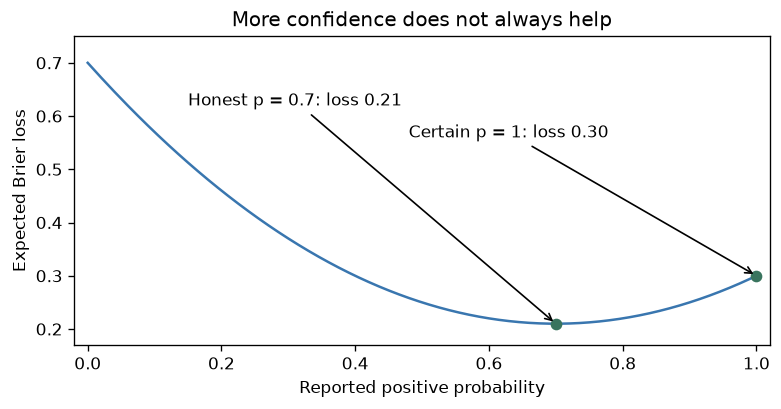

In [7]:
theta = .7
grid = np.linspace(0, 1, 201)
expected_loss = theta*(grid-1)**2 + (1-theta)*grid**2
np.testing.assert_allclose(expected_loss, theta*(1-theta)+(grid-theta)**2)
fig, ax = plt.subplots(figsize=(6.4, 3.3), layout="constrained")
ax.plot(grid, expected_loss, color="#3976AF")
ax.scatter([theta, 1], [.21, .30], color="#39745E", zorder=3)
ax.annotate("Honest p = 0.7: loss 0.21", (.7, .21), xytext=(.15, .62),
            arrowprops={"arrowstyle": "->"})
ax.annotate("Certain p = 1: loss 0.30", (1, .3), xytext=(.48, .56),
            arrowprops={"arrowstyle": "->"})
ax.set(xlabel="Reported positive probability", ylabel="Expected Brier loss",
       title="More confidence does not always help", xlim=(-.02, 1.02), ylim=(.17, .75))
display(fig)
plt.close(fig)
print("Expected loss at p=0.7 and p=1:", .21, .30)

## 5. Keep a held-out row out of fitting

A blank in the days column needs a replacement value. The
encoder learns that value and the known channel names from the
four training orders. Each position in `train_numeric` and
`train_channels` refers to the same order. `None` marks a blank.

The observed training days are 2, 4, and 8. Their middle value
is 4, so the fitted median is 4. The distinct observed channels
in alphabetical order are `shop` and `web`. That order sets
the positions for the two known-channel indicators. Each
indicator is 1 when its condition holds and 0 otherwise.

In [8]:
from examples.ch29_tabular.model import encode_rows, fit_row_encoder

train_numeric = [2, 4, None, 8]
train_channels = ["web", "shop", None, "web"]
median, levels = fit_row_encoder(train_numeric, train_channels)

assert median == 4
assert levels == ("shop", "web")

columns = (
    "filled days",
    "days missing",
    *levels,
    "channel missing",
    "channel unknown",
)
print(f"Training median = {median:g}")
print("Output columns in order")
for position, name in enumerate(columns, start=1):
    print(f"{position}. {name}")

Training median = 4
Output columns in order
1. filled days
2. days missing
3. shop
4. web
5. channel missing
6. channel unknown


Apply this fit to the three held-out orders. The row with a
blank days value gets 4 and a 1 in `days missing`. Its channel
`kiosk` was unseen during training, so
`channel unknown` is 1. The row with 6 days and channel `shop`
keeps 6 and activates `shop`. The row with 100 days and a blank
channel keeps 100 and activates `channel missing`. Both `kiosk`
and the blank channel leave the `shop` and `web` entries at 0.

In [9]:
held_out_numeric = [None, 6, 100]
held_out_channels = ["kiosk", "shop", None]
held_out_features = encode_rows(
    held_out_numeric, held_out_channels, median, levels
)
expected_held_out = [
    [4,   1, 0, 0, 0, 1],
    [6,   0, 1, 0, 0, 0],
    [100, 0, 0, 0, 1, 0],
]
np.testing.assert_array_equal(held_out_features, expected_held_out)
assert held_out_features.shape == (3, len(columns))
print(f"Held-out shape {held_out_features.shape}")
print(held_out_features)

Held-out shape (3, 6)
[[  4.   1.   0.   0.   0.   1.]
 [  6.   0.   1.   0.   0.   0.]
 [100.   0.   0.   0.   1.   0.]]


Append the order with 12 days and channel `mobile`. Pass the
same median and levels to `encode_rows`. The extra row keeps
its observed value 12 and uses the existing `channel unknown`
flag. The four-row result still has six columns, and its first
three rows match the original output. The held-out values 100
and 12 appear in their own rows. The median used to fill the
blank came from the training days $(2,4,8)$.

In [10]:
extended_features = encode_rows(
    held_out_numeric + [12],
    held_out_channels + ["mobile"],
    median,
    levels,
)
assert extended_features.shape == (4, len(columns))
np.testing.assert_array_equal(extended_features[:3], held_out_features)
np.testing.assert_array_equal(extended_features[3], [12, 0, 0, 0, 0, 1])
print(f"Extended held-out shape {extended_features.shape}")
print(extended_features)

Extended held-out shape (4, 6)
[[  4.   1.   0.   0.   0.   1.]
 [  6.   0.   1.   0.   0.   0.]
 [100.   0.   0.   0.   1.   0.]
 [ 12.   0.   0.   0.   0.   1.]]


## 6. Test the effect of an unseen category

Use the fit from Exercise 5 and hold the days value at 6.
Change only the channel. The two numerical entries should be
$(6,0)$ in every row because 6 is an observed number. The last
four columns tell us which of the three channel cases applies.

In [11]:
channel_examples = ["shop", "kiosk", None]
comparison_features = encode_rows(
    [6, 6, 6], channel_examples, median, levels
)

np.testing.assert_array_equal(
    comparison_features[:, :2], [[6, 0], [6, 0], [6, 0]]
)
np.testing.assert_array_equal(
    comparison_features[:, 2:], [[1, 0, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]]
)
print("Channel   Encoded row")
for channel, row in zip(channel_examples, comparison_features):
    print(f"{str(channel):<9} {row}")

Channel   Encoded row
shop      [6. 0. 1. 0. 0. 0.]
kiosk     [6. 0. 0. 0. 0. 1.]
None      [6. 0. 0. 0. 1. 0.]


For `shop`, the 1 is in column 3, the known `shop` indicator.
For `kiosk`, it moves to column 6 because the channel is present
and absent from the training vocabulary. For `None`, it moves
to column 5 because the channel itself is missing. Column 4,
the indicator for `web`, is 0 throughout. The numerical columns
agree exactly. The distinction between an unseen channel and
a blank one is carried by two separate categorical flags.

The unknown flag retains the fact that a supplied category was unseen.
It does not retain its name: mobile and kiosk have identical encodings when
the numerical value is held fixed. A model trained with an always-zero unknown
column has no observed outcomes for that indicator. A fallback or a training
strategy for rare and unseen levels must be designed and validated separately.

In [12]:
mobile = encode_rows([6], ["mobile"], median, levels)
np.testing.assert_array_equal(mobile[0], comparison_features[1])
training_features = encode_rows(train_numeric, train_channels, median, levels)
assert np.all(training_features[:, -1] == 0)
print("Mobile equals kiosk:", np.array_equal(mobile[0], comparison_features[1]))
print("Unknown column in training:", training_features[:, -1])

Mobile equals kiosk: True
Unknown column in training: [0. 0. 0. 0.]


## 7. Trace the influence of a context row

Think of a query order whose label we want to predict. The first two
context orders have positive labels. The third has a negative label,
and the query receives a higher similarity score for that order.
We will raise the third score and see how much influence it gains.

Softmax exponentiates the scores and divides by the sum of those
exponentials. With scores $(0,0,\ln 4)$, the exponentials are
$(1,1,4)$, which sum to $6$. The weights are
$(1/6,1/6,4/6)$. The toy predictor multiplies each weight by its
row's label and adds the products. Only the first two labels are 1,
so the initial positive-class estimate is

$$
\widehat{p}
= \frac{1}{6}(1) + \frac{1}{6}(1) + \frac{4}{6}(0)
= \frac{1}{3}.
$$

Raising the last score by $\ln 2$ makes it $\ln 8$. Its exponential
doubles from $4$ to $8$, while the first two stay at $1$. The new
denominator is $10$, so the weights are $(1/10,1/10,8/10)$. The
estimate becomes $1/10+1/10=1/5$. The table below checks both
predictions and all six weights against these hand calculations.

In [13]:
import math

from examples.ch29_tabular.model import context_probability

context_labels = [1, 1, 0]
original_scores = np.array([0.0, 0.0, math.log(4)])
raised_scores = original_scores.copy()
raised_scores[-1] += math.log(2)

original_p, original_weights = context_probability(
    original_scores, context_labels
)
raised_p, raised_weights = context_probability(
    raised_scores, context_labels
)

np.testing.assert_allclose(original_weights, [1 / 6, 1 / 6, 4 / 6])
np.testing.assert_allclose(raised_weights, [1 / 10, 1 / 10, 8 / 10])
np.testing.assert_allclose([original_p, raised_p], [1 / 3, 1 / 5])
np.testing.assert_allclose(raised_p - original_p, -2 / 15)

print("Setting          Row 1     Row 2     Row 3   P(label = 1)")
for setting, weights, probability in [
    ("Original", original_weights, original_p),
    ("Raised row 3", raised_weights, raised_p),
]:
    weights_text = "  ".join(f"{weight:8.5f}" for weight in weights)
    print(f"{setting:13s}  {weights_text}  {probability:11.5f}")

Setting          Row 1     Row 2     Row 3   P(label = 1)
Original        0.16667   0.16667   0.66667      0.33333
Raised row 3    0.10000   0.10000   0.80000      0.20000


The negative row takes $8/10$ of the weight after the change,
compared with $4/6$ before. Because the three weights must sum to
one, less weight remains for the two positive rows. The negative
row's extra weight contributes zero to the weighted label sum, and
the estimate drops from about $0.33333$ to $0.20000$. A larger
similarity means more influence for that context row. The direction
of the probability change depends on its label.

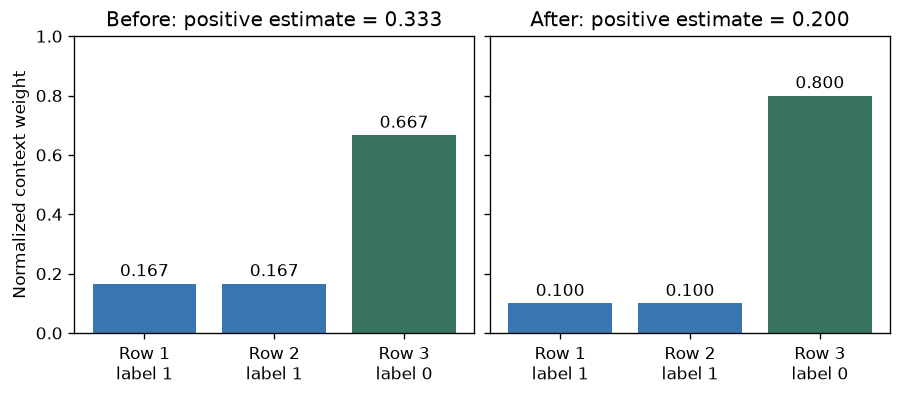

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.2), sharey=True,
                         layout="constrained")
for ax, w, p, name in zip(axes, [original_weights, raised_weights],
                          [original_p, raised_p], ["Before", "After"]):
    ax.bar(range(3), w, color=["#3976AF", "#3976AF", "#39745E"])
    ax.set_xticks(range(3), ["Row 1\nlabel 1", "Row 2\nlabel 1", "Row 3\nlabel 0"])
    ax.set(ylim=(0, 1), title=f"{name}: positive estimate = {p:.3f}")
    for j, value in enumerate(w):
        ax.text(j, value+.025, f"{value:.3f}", ha="center")
axes[0].set_ylabel("Normalized context weight")
display(fig)
plt.close(fig)

## 8. Score two confidence levels

Suppose two predictors classify the same four orders. Each gives
a probability of label 1. Let A give $(0.2,0.7,0.8,0.1)$ and B
give $(0.45,0.55,0.6,0.4)$. The observed labels are $(0,1,1,0)$.

At threshold $0.5$, assign label 1 when $p_i\ge 0.5$ and label 0
otherwise. Each predictor gives $(0,1,1,0)$, so both get all four
decisions right and achieve accuracy $4/4=1$.

In the chapter's binary convention, each case contributes the
squared difference between its positive-class probability $p_i$
and its observed label $y_i$. The Brier score is the mean of
those contributions.

$$
\mathrm{Brier} = \frac{1}{4}\sum_{i=1}^4 (p_i-y_i)^2.
$$

| Case | Label | A probability | A squared error | B probability | B squared error |
|---:|---:|---:|---:|---:|---:|
| 1 | 0 | 0.20 | 0.0400 | 0.45 | 0.2025 |
| 2 | 1 | 0.70 | 0.0900 | 0.55 | 0.2025 |
| 3 | 1 | 0.80 | 0.0400 | 0.60 | 0.1600 |
| 4 | 0 | 0.10 | 0.0100 | 0.40 | 0.1600 |

For example, the second case has label 1. A assigns it $0.7$,
giving $(0.7-1)^2=0.09$. B assigns it $0.55$, giving
$(0.55-1)^2=0.2025$. The sums are $0.18$ for A and $0.725$ for
B, so the scores are $0.045$ and $0.18125$ respectively.

In [15]:
from examples.ch29_tabular.model import brier_score

observed_labels = np.array([0, 1, 1, 0])
probability_rows = [
    ("A", np.array([0.2, 0.7, 0.8, 0.1])),
    ("B", np.array([0.45, 0.55, 0.6, 0.4])),
]
expected_errors = {
    "A": [0.04, 0.09, 0.04, 0.01],
    "B": [0.2025, 0.2025, 0.16, 0.16],
}
expected_brier = {"A": 0.045, "B": 0.18125}

for name, probabilities in probability_rows:
    decisions = (probabilities >= 0.5).astype(int)
    accuracy = float(np.mean(decisions == observed_labels))
    squared_errors = (probabilities - observed_labels) ** 2
    score = brier_score(observed_labels, probabilities)

    np.testing.assert_array_equal(decisions, [0, 1, 1, 0])
    np.testing.assert_allclose(squared_errors, expected_errors[name])
    np.testing.assert_allclose(score, expected_brier[name])
    assert accuracy == 1.0

    errors_text = ", ".join(f"{error:.4f}" for error in squared_errors)
    print(f"Predictor {name}")
    print(f"  Decisions      {decisions.tolist()}")
    print(f"  Accuracy       {accuracy:.1%}")
    print(f"  Squared errors [{errors_text}]")
    print(f"  Brier score    {score:.5f}")

Predictor A
  Decisions      [0, 1, 1, 0]
  Accuracy       100.0%
  Squared errors [0.0400, 0.0900, 0.0400, 0.0100]
  Brier score    0.04500
Predictor B
  Decisions      [0, 1, 1, 0]
  Accuracy       100.0%
  Squared errors [0.2025, 0.2025, 0.1600, 0.1600]
  Brier score    0.18125


A and B make the same decisions, but A assigns probabilities closer
to the observed labels in every case. A therefore gets the lower
Brier score on these four cases. Accuracy at 0.5 gives both
predictors the same credit because it only sees the decisions.

Calibration asks whether events assigned a given probability occur
about that often. For example, among many independent orders that
receive predictions near 0.7, the observed fraction of positive
labels should be near 0.7. A single order receiving 0.7 has only
one outcome, so it tells us little about that frequency.

To compare calibration, collect many held-out predictions and
outcomes from the intended deployment population. Group each
predictor's probabilities into the same ranges and compare the
mean predicted probability with the observed positive rate in
each range. Report how many orders fall in each range and attach
uncertainty intervals, accounting for repeated customers if their
orders are related. This can reveal where a predictor's
probabilities run systematically high or low. The Brier scores
here compare overall probability error on the four given cases.

Now construct the separate 20-case calibration example. The first ten
labels contain two positives; the next ten contain eight. A constant predictor
assigns 0.5 to all cases, matching the overall rate $10/20$. A second predictor
assigns 0.2 to the first group and 0.8 to the second, matching $2/10$ and $8/10$.
Thus both match observed frequencies at their prediction values.

The constant predictor has loss $(0.5-y)^2=0.25$ on every case. In the first
group, the second predictor's mean loss is
$(2(0.8)^2+8(0.2)^2)/10=0.16$; the second group gives the same result.
It distinguishes risk groups and has lower Brier loss despite both predictors'
perfect empirical calibration. This deliberately constructed example is not
evidence that 20 observations suffice to validate calibration in deployment.

Brier constant / two groups: [0.25 0.16]


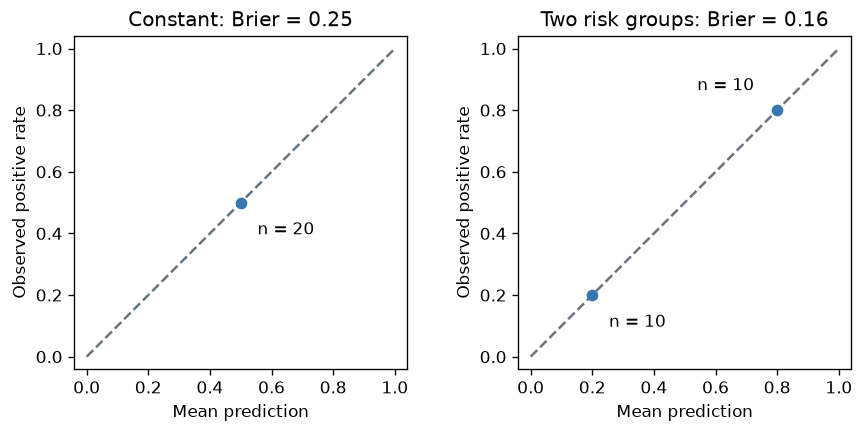

In [16]:
calibration_labels = np.array([1]*2 + [0]*8 + [1]*8 + [0]*2)
calibration_predictions = [np.full(20, .5), np.repeat([.2, .8], 10)]
calibration_scores = [brier_score(calibration_labels, p)
                      for p in calibration_predictions]
np.testing.assert_allclose(calibration_scores, [.25, .16])
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.5), layout="constrained")
for ax, p, score, name in zip(axes, calibration_predictions, calibration_scores,
                              ["Constant", "Two risk groups"]):
    ax.plot([0, 1], [0, 1], "--", color="#687580")
    for value in np.unique(p):
        mask = p == value
        rate = calibration_labels[mask].mean()
        assert np.isclose(value, rate)
        ax.scatter(value, rate, color="#3976AF", zorder=3)
        offset = (-48, 12) if value > .7 else (10, -19)
        ax.annotate(f"n = {mask.sum()}", (value, rate), xytext=offset,
                    textcoords="offset points")
    ax.set(xlim=(-.04, 1.04), ylim=(-.04, 1.04), aspect="equal",
           xlabel="Mean prediction", ylabel="Observed positive rate",
           title=f"{name}: Brier = {score:.2f}")
display(fig)
plt.close(fig)
print("Brier constant / two groups:", np.round(calibration_scores, 2))

## 9. Split for the intended customer

For new customers, one valid design assigns 350 customer IDs to training,
75 to validation, and 75 to test. Every order follows its customer's split.
Verify disjoint ID sets and report row and class counts: customers with five
orders contribute more rows than customers with one. Fit preprocessing and
models on training customers and choose settings on validation customers.
For a first-order deployment question, score the first eligible order only.
If later orders from held-out customers are included, state that population
or report them separately. History features must still obey each order's timestamp.

For later orders from existing customers, use global time cutoffs. For example,
train on orders placed through April, validate on June, and test on August.
An August test customer must have an order known before August; apply the
analogous rule to June. Earlier and later rows from the same ID are allowed
because that is the intended task. Separate per-customer cutoffs could wrongly
train on one person's August order while predicting another person's June order.

If labels require 30 days to mature, leave May and July for outcomes to arrive.
An April 30 order matures on May 30, before June evaluation; a June 30 label
matures on July 30, before August testing. Recent orders may supply history while
their labels remain unavailable for fitting or context. Freeze each fit and
selection using only outcomes then known; score August outcomes after their
observation windows finish. A customer with only an earlier order has no later
test order. Report eligible customers and rows.

The fixture gives customer $i$ exactly $1+(i\bmod5)$ orders. It checks split
counts, not predictive performance. Averaging order losses weights frequent
customers more; averaging each customer's mean loss gives equal customer weight.

In [17]:
from datetime import date, timedelta

customer_ids = np.arange(500)
order_customer = np.repeat(customer_ids, 1+customer_ids % 5)
groups = [set(range(350)), set(range(350, 425)), set(range(425, 500))]
assert all(groups[i].isdisjoint(groups[j]) for i in range(3) for j in range(i))
row_counts = [sum(int(c) in group for c in order_customer) for group in groups]
assert row_counts == [1050, 225, 225]
print("Customer counts:", [len(g) for g in groups])
print("Order counts:", row_counts)
for last_order, next_period in [(date(2026, 4, 30), date(2026, 6, 1)),
                                (date(2026, 6, 30), date(2026, 8, 1))]:
    label_ready = last_order + timedelta(days=30)
    assert label_ready < next_period
    print("Last label matures:", label_ready, "before", next_period)
loss = np.array([.04]*5 + [.64])
owner = np.array(["A"]*5 + ["B"])
row_mean = loss.mean()
customer_mean = np.mean([loss[owner == c].mean() for c in np.unique(owner)])
np.testing.assert_allclose([row_mean, customer_mean], [.14, .34])
print("Illustrative order-weighted / customer-weighted Brier:", row_mean, customer_mean)

Customer counts: [350, 75, 75]
Order counts: [1050, 225, 225]
Last label matures: 2026-05-30 before 2026-06-01
Last label matures: 2026-07-30 before 2026-08-01
Illustrative order-weighted / customer-weighted Brier: 0.14 0.34


## 10. Compare three methods fairly

Compare logistic regression, a gradient-boosted tree ensemble and a frozen
TabPFN classification checkpoint on one fixed task. Define the label and
prediction time, then give every method the same available input fields.
Exclude outcome-revealing fields such as later refund amounts.

Use a deployment-matched split, such as the grouped new-customer design.
Draw nested subsets of 25, 50, 100 and 200 training customers. Use every eligible
labeled order from each chosen customer and give the same labeled rows to all
three methods. Each larger subset contains the smaller one. Report the actual
row counts, and use sizes supported by the chosen checkpoint. Repeat with
recorded seeds. A prespecified sampling rule based only on training labels can
require both classes in the smallest subset; logistic classification needs both.
Disclose that rule because it changes the sampling design.

At each size, fit the logistic weights, tree model and data-dependent preprocessing
from that subset only. Different methods may have different appropriate
preprocessing. The frozen model receives the subset's features and labels as
context; queries supply available features without true labels. Record the
checkpoint revision, feature types and context construction. Equal task-label
budgets do not erase the pretrained model's earlier synthetic training.

Use validation to select regularization, tree settings, context choices and
decision thresholds, with disclosed tuning budgets. Keep test cases fixed at
every size and never use their labels for choices. Report decision and probability
scores, including Brier loss, with variability across subset draws. Account for
customer dependence when estimating uncertainty. Separate fit, checkpoint load,
context preparation, first-query and repeated-query costs; report hardware and
memory. A changing learning curve reflects both the amount and composition of
the selected training information.

The executable fixture below checks nested subsets and row budgets. Its labels
are synthetic and it trains no models; producing invented benchmark curves
would not answer this design exercise.

In [18]:
rng = np.random.default_rng(28)
training_customers = np.arange(350)
permutation = rng.permutation(training_customers)
sizes = [25, 50, 100, 200]
subsets = [set(permutation[:n]) for n in sizes]
assert all(a.issubset(b) for a, b in zip(subsets, subsets[1:]))
train_orders = order_customer[order_customer < 350]
synthetic_labels = train_orders % 2
for size, subset in zip(sizes, subsets):
    selected = np.array([c in subset for c in train_orders])
    assert set(synthetic_labels[selected]) == {0, 1}
    assert not (subset & groups[1]) and not (subset & groups[2])
    print(f"{size:3d} customers -> {selected.sum():3d} identical labeled rows per method")
print("Validation/test customers remain fixed; no benchmark scores fabricated.")

 25 customers ->  75 identical labeled rows per method
 50 customers -> 145 identical labeled rows per method
100 customers -> 295 identical labeled rows per method
200 customers -> 599 identical labeled rows per method
Validation/test customers remain fixed; no benchmark scores fabricated.


## 11. Investigate unreliable probabilities

Suppose the predictions in the bin $[0.7,0.8)$ average 0.74 and its observed
positive rate is 0.50. Compare 0.50 with the actual mean 0.74, not the midpoint
0.75: the gap is $-0.24$. First count orders, positives and distinct customers.
Two positives in four cases and 200 in 400 give the same rate with very different
precision. Confirm that all outcome windows have matured; pending returns can
make an apparent low rate misleading.

Measure overlap with training and earlier validation customers. Report new and
existing customers separately when counts permit. Repeated orders reduce the
amount of independent information. Resample whole customers for a customer-based
uncertainty analysis and inspect time blocks if common shocks create temporal
dependence. A pooled interval can hide a change concentrated in one week.

Compare inputs as they existed at prediction time: channel shares, missing and
unseen-category rates, numerical distributions and the fraction of new customers.
Compare positive rates after labels mature. Feature drift concerns the inputs;
outcomes can also change at similar inputs. Evaluate the same frozen model with
the same bin boundaries in an earlier validation period, reporting mean
probabilities, observed rates and counts.

Treat the latest data examined above as a diagnostic period. Fit any recalibration
on a separate labeled period, for example a logistic map of the model's log-odds
$\ln(p/(1-p))$, with a fixed endpoint-clipping rule. Freeze the map and evaluate
original and adjusted probabilities on the same later untouched test orders.
Compare reliability, counts and Brier loss, with uncertainty. Do not replace all
future predictions by the observed diagnostic rate and call that validation.

The code checks half-open bin boundaries and the denominator. It intentionally
does not fit a recalibrator to the diagnostic outcomes.

In [19]:
diagnostic_p = np.array([.69, .70, .74, .74, .78, .80])
diagnostic_y = np.array([0, 1, 0, 1, 0, 1])
diagnostic_customer = np.array(["A", "B", "B", "C", "D", "E"])
in_bin = (diagnostic_p >= .7) & (diagnostic_p < .8)
assert in_bin.tolist() == [False, True, True, True, True, False]
n_orders = in_bin.sum()
n_customers = np.unique(diagnostic_customer[in_bin]).size
mean_p = diagnostic_p[in_bin].mean()
rate = diagnostic_y[in_bin].mean()
np.testing.assert_allclose([mean_p, rate, rate-mean_p], [.74, .5, -.24])
assert (n_orders, n_customers) == (4, 3)
print("Orders / distinct customers:", n_orders, n_customers)
print("Mean prediction / observed rate / gap:", mean_p, rate, rate-mean_p)

Orders / distinct customers: 4 3
Mean prediction / observed rate / gap: 0.74 0.5 -0.24


In [20]:
# Label availability is checked before estimating a diagnostic return rate.
issued = [date(2026, 8, 1), date(2026, 8, 20), date(2026, 8, 31)]
audit_date = date(2026, 9, 15)
mature = [d + timedelta(days=30) <= audit_date for d in issued]
assert mature == [True, False, False]
print("Outcome window complete on audit date:", mature)
print("Wait for remaining labels or report a clearly defined mature cohort.")
print("Fit recalibration separately; score it on a later untouched period.")

Outcome window complete on audit date: [True, False, False]
Wait for remaining labels or report a clearly defined mature cohort.
Fit recalibration separately; score it on a later untouched period.
